# Day 08 | Neural Networks: From Inputs to Predictions

**KGP Talkie | Day 08**

Run the cells from top to bottom. The small examples show how a prediction is made. The main example uses the scikit-learn breast cancer dataset.

## Setup

This notebook needs NumPy, pandas, Matplotlib, and scikit-learn. If a library is missing, run `%pip install numpy pandas matplotlib scikit-learn` in a new cell, then restart the kernel.

## 1. Import the tools

An import loads a tool so that our code can use it. We start with NumPy for the small number examples.

In [1]:
from sklearn import set_config
set_config(display="text")

import numpy as np  # np is the common short name for NumPy.

## 2. One neuron predicts a number

An input is a value given to the model. A target is its known answer. A weight multiplies an input; a bias is added afterwards.

A classic **perceptron** uses a step activation to choose a class. Here we first use a **linear neuron**: it keeps the predicted number. This lets us use the two-row example before adding a class rule.

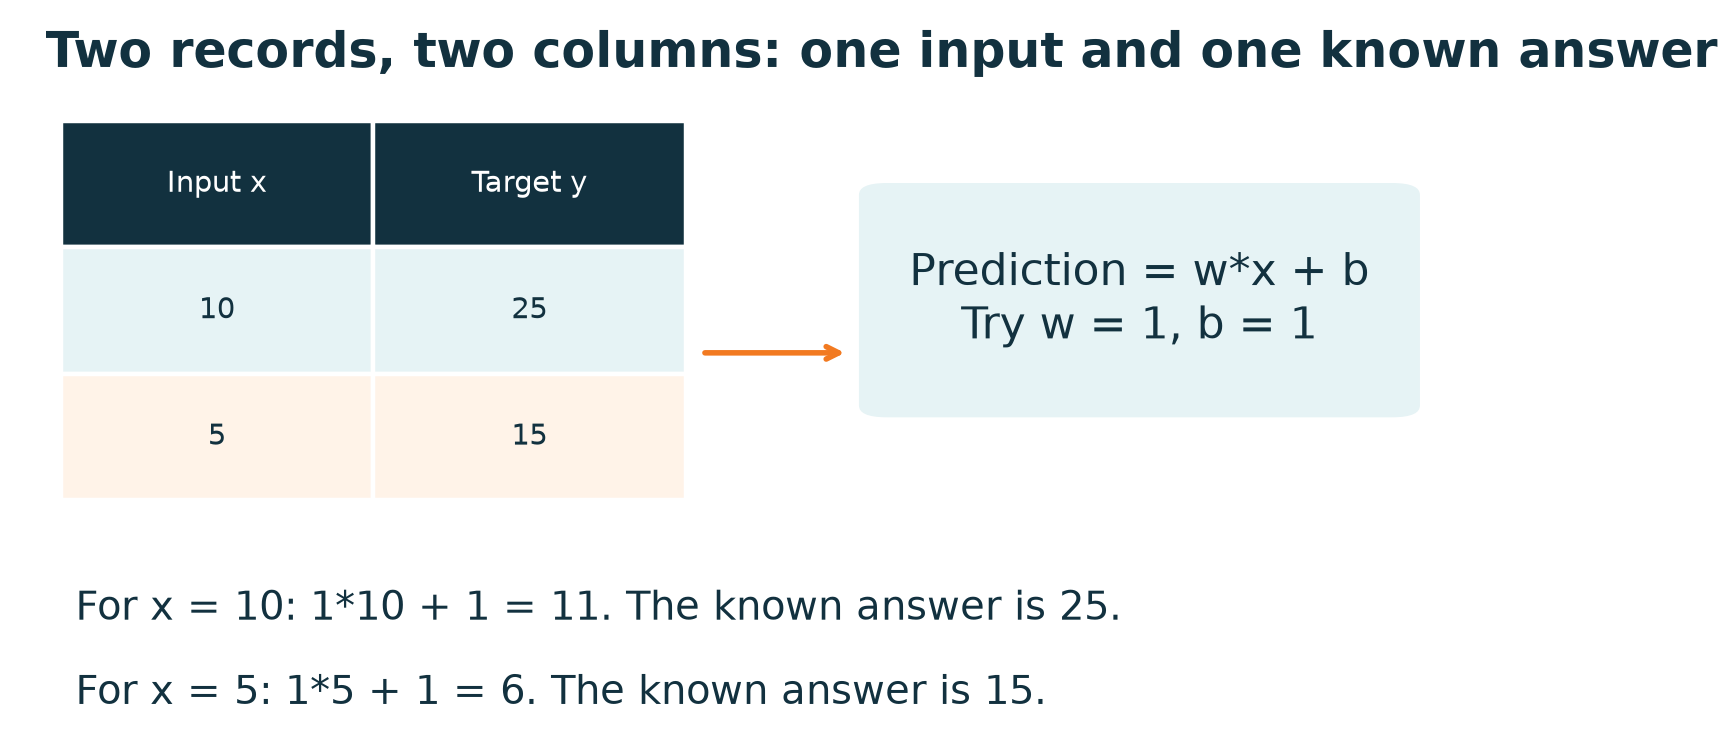

The resource uses x=10 with y=25 and x=5 with y=15. A linear output keeps the number instead of applying a class step.

In [2]:
x_small = np.array([10, 5])  # Two input records.

In [3]:
y_small = np.array([25, 15])  # One known target for each record.

In [4]:
weight = 1  # A starting candidate, not a learned final value.

In [5]:
bias = 1  # Added to every prediction.

In [6]:
small_predictions = weight * x_small + bias  # Apply the same rule to both inputs.

In [7]:
small_predictions  # Predictions are 11 and 6.

array([11,  6])

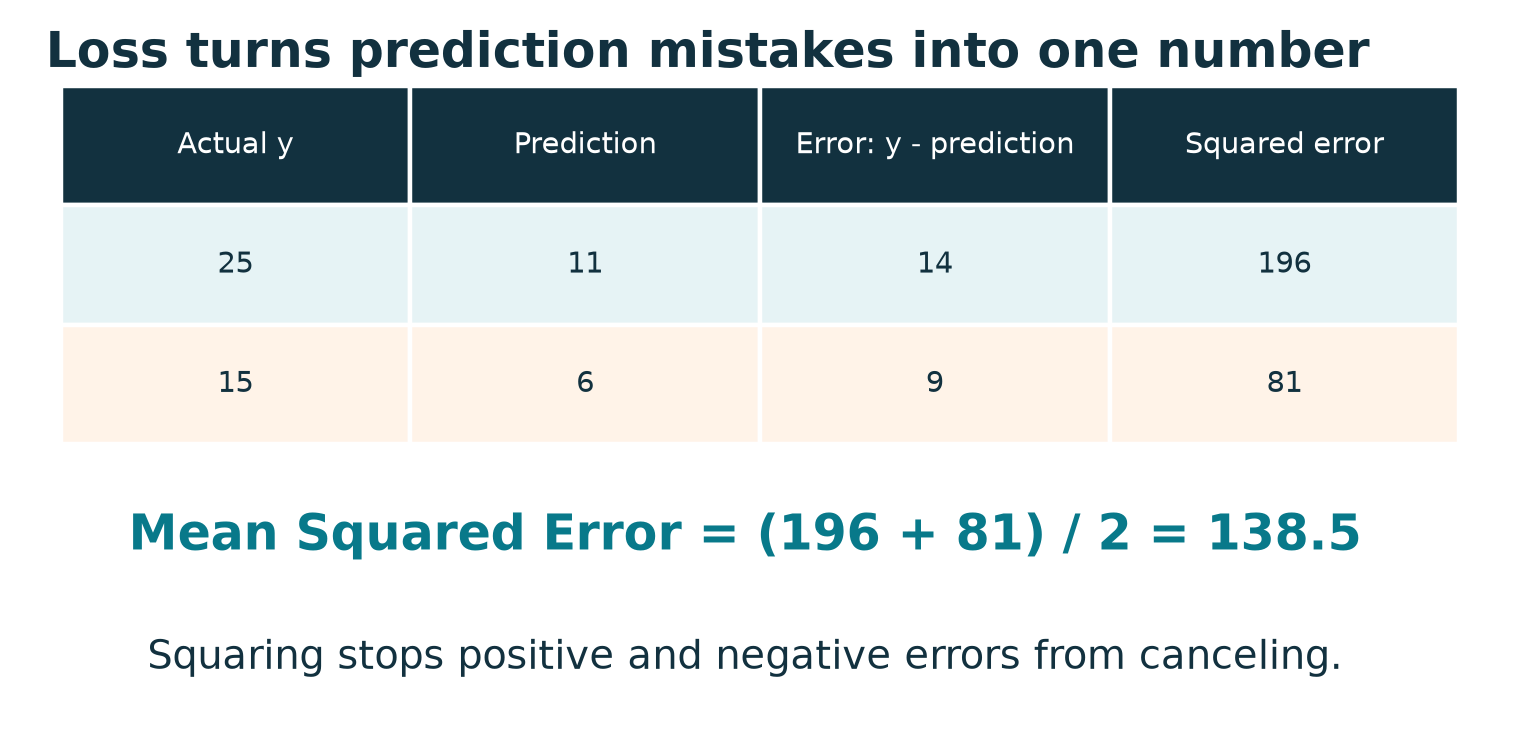

With weight 1 and bias 1, the two squared errors are 196 and 81. Their mean is 138.5.

In [8]:
errors = y_small - small_predictions  # Compare each target with its own prediction.

In [9]:
squared_errors = errors ** 2  # **2 squares each error so signs cannot cancel.

In [10]:
np.mean(squared_errors)  # Mean Squared Error: one loss value, 138.5.

np.float64(138.5)

A **loss** is a number used to judge mistakes during training. Here lower loss means the predictions are closer to the two known targets. The following weight and bias fit these two records. A training optimizer normally learns values by taking repeated steps.

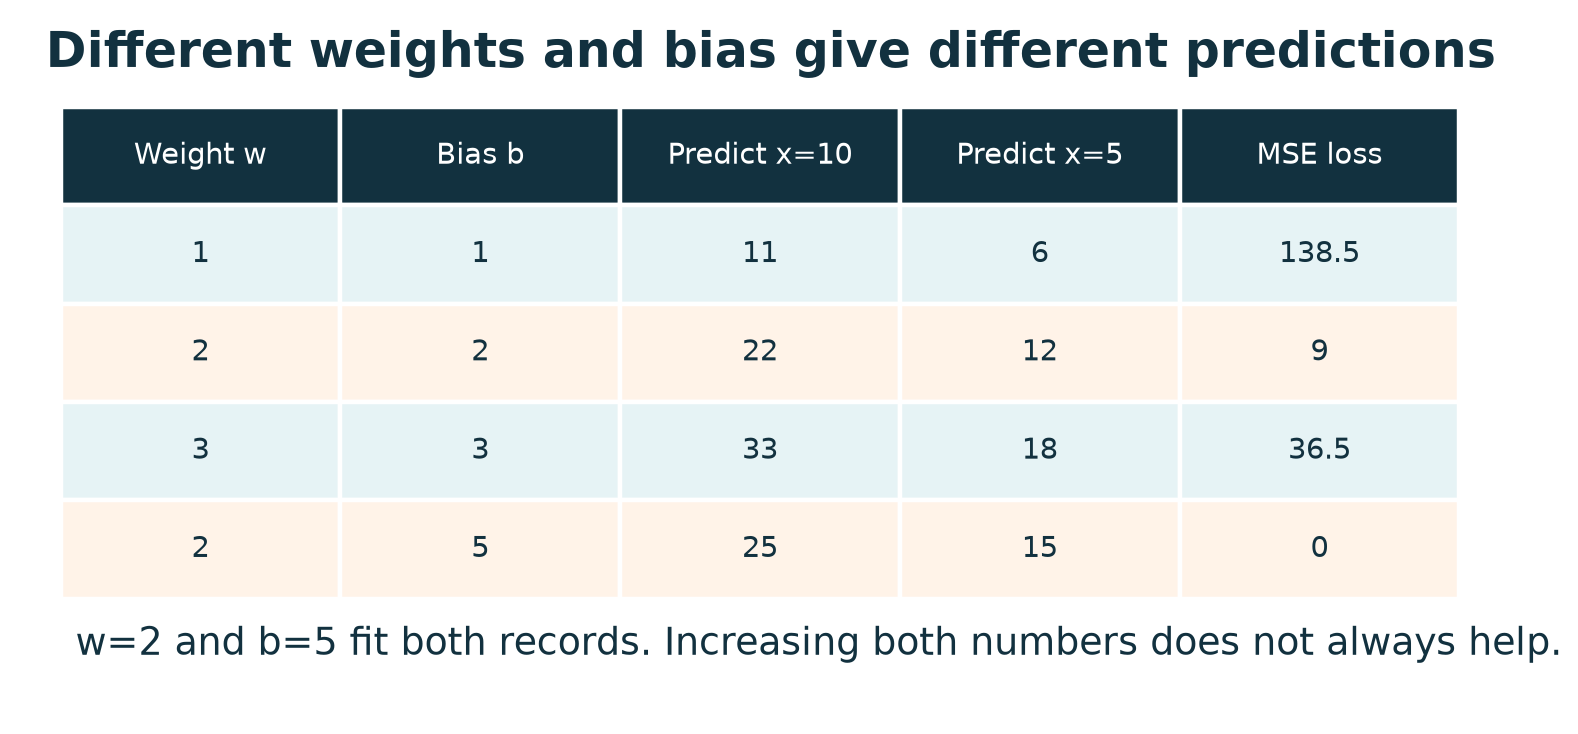

The same two records are checked with four candidate settings. Weight 3 and bias 3 predict 33 and 18, not 33 and 6.

In [11]:
weight = 2  # The candidate that fits both records in this example.

In [12]:
bias = 5

In [13]:
small_predictions = weight * x_small + bias

In [14]:
small_predictions  # Now the predictions are 25 and 15.

array([25, 15])

In [15]:
np.mean((y_small - small_predictions) ** 2)  # Zero loss on these two records only.

np.float64(0.0)

## 3. A perceptron with two inputs

**X** is a table of inputs. Two rows and two feature columns give shape `(2, 2)`. The class target is stored separately. Each feature has one weight.

A **step activation** is a rule: in this example, a score of 0 or more gives class 1; a negative score gives class 0. These chosen weights show the calculation; they are not a fitted model.

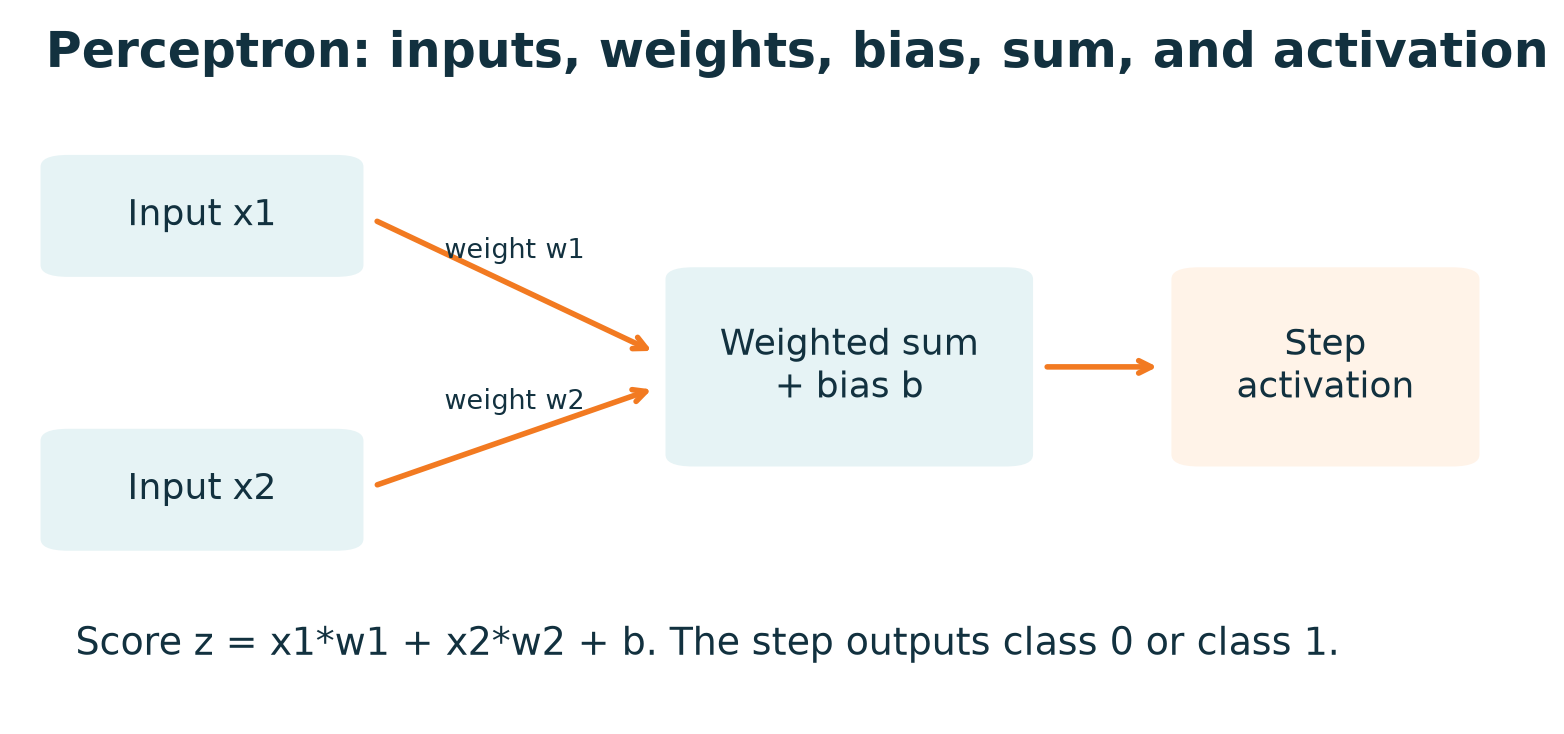

A classic perceptron multiplies inputs by weights, adds a bias, then uses a step rule to choose class 0 or 1.

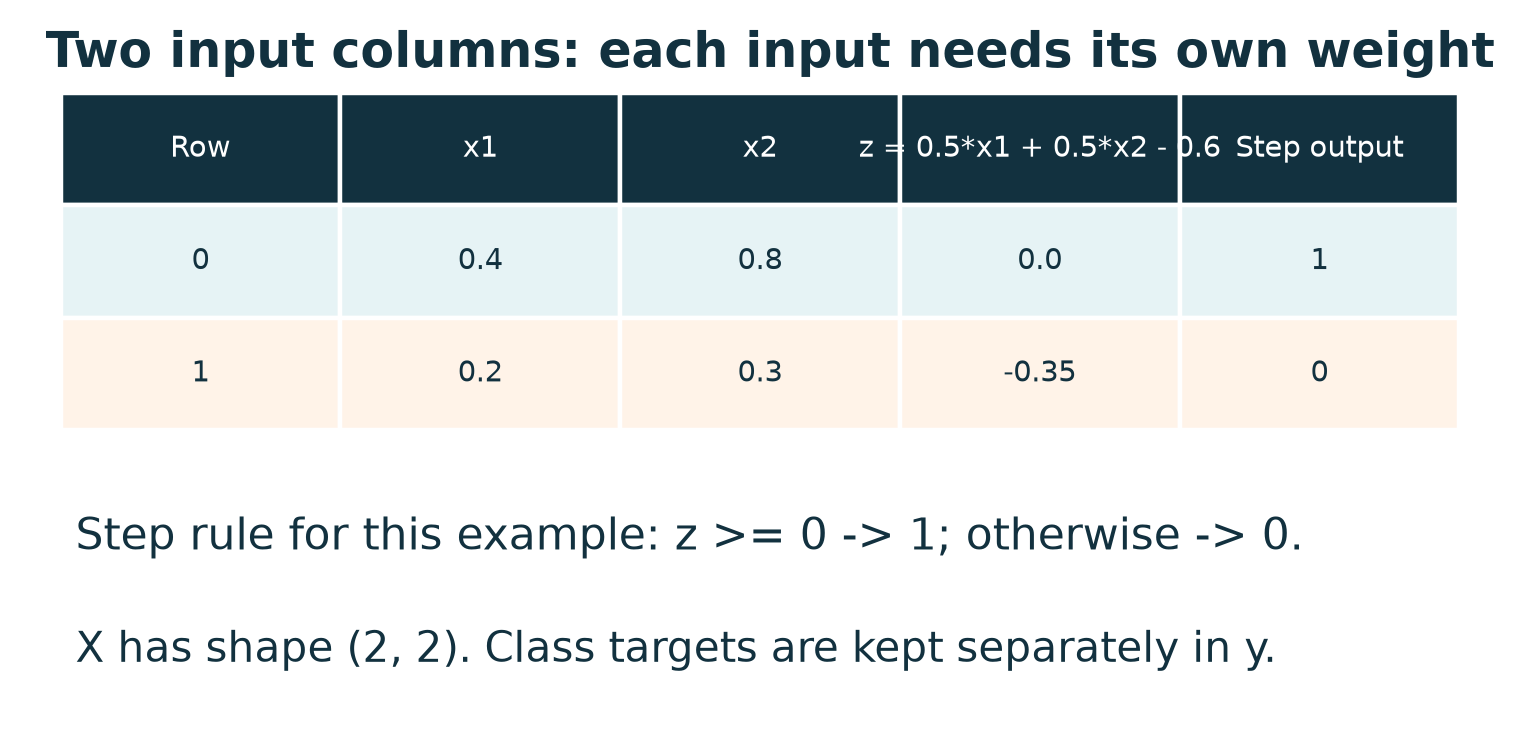

Two rows and two feature columns give X shape (2, 2). Every row uses the same two weights and bias.

In [16]:
X_small = np.array([[0.4, 0.8], [0.2, 0.3]])  # One record per row.

In [17]:
weights = np.array([0.5, 0.5])  # One weight for each of the two columns.

In [18]:
bias = -0.6  # Shift the cut point used by the step rule.

In [19]:
weighted_inputs = X_small * weights  # Match each feature column with its weight.

In [20]:
weighted_inputs  # Row 0 becomes [0.2, 0.4]; row 1 becomes [0.1, 0.15].

array([[0.2 , 0.4 ],
       [0.1 , 0.15]])

In [21]:
scores = weighted_inputs.sum(axis=1) + bias  # axis=1 adds across the columns of each row.

In [22]:
scores  # Scores are about 0 and -0.35; decimal storage may show a tiny value near 0.

array([ 1.11022302e-16, -3.50000000e-01])

In [23]:
class_predictions = (scores >= 0).astype(int)  # Compare scores, then turn True/False into 1/0.

In [24]:
class_predictions

array([1, 0])

## 4. A network links many neurons

An **input layer** receives the features. A **hidden layer** makes new values from them. An **output layer** returns a prediction. A **Multilayer Perceptron (MLP)** links these layers.

Forward propagation makes predictions. Backpropagation calculates how changes in each weight and bias would change the loss. An optimizer uses that information to update the values. A learning rate controls the size of update steps.

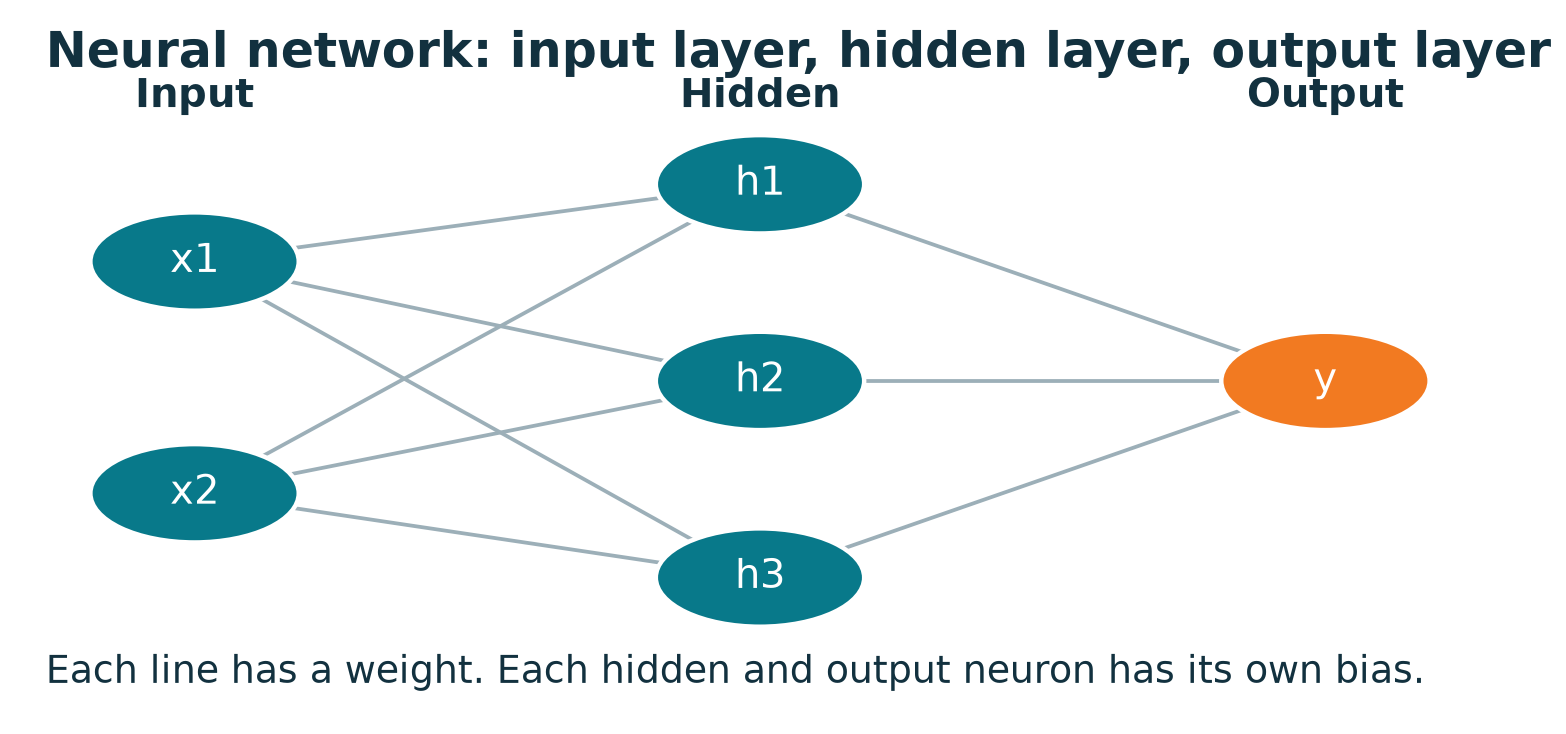

Two input values reach three hidden neurons. Each hidden neuron learns its own weights and bias. The output combines the hidden results.

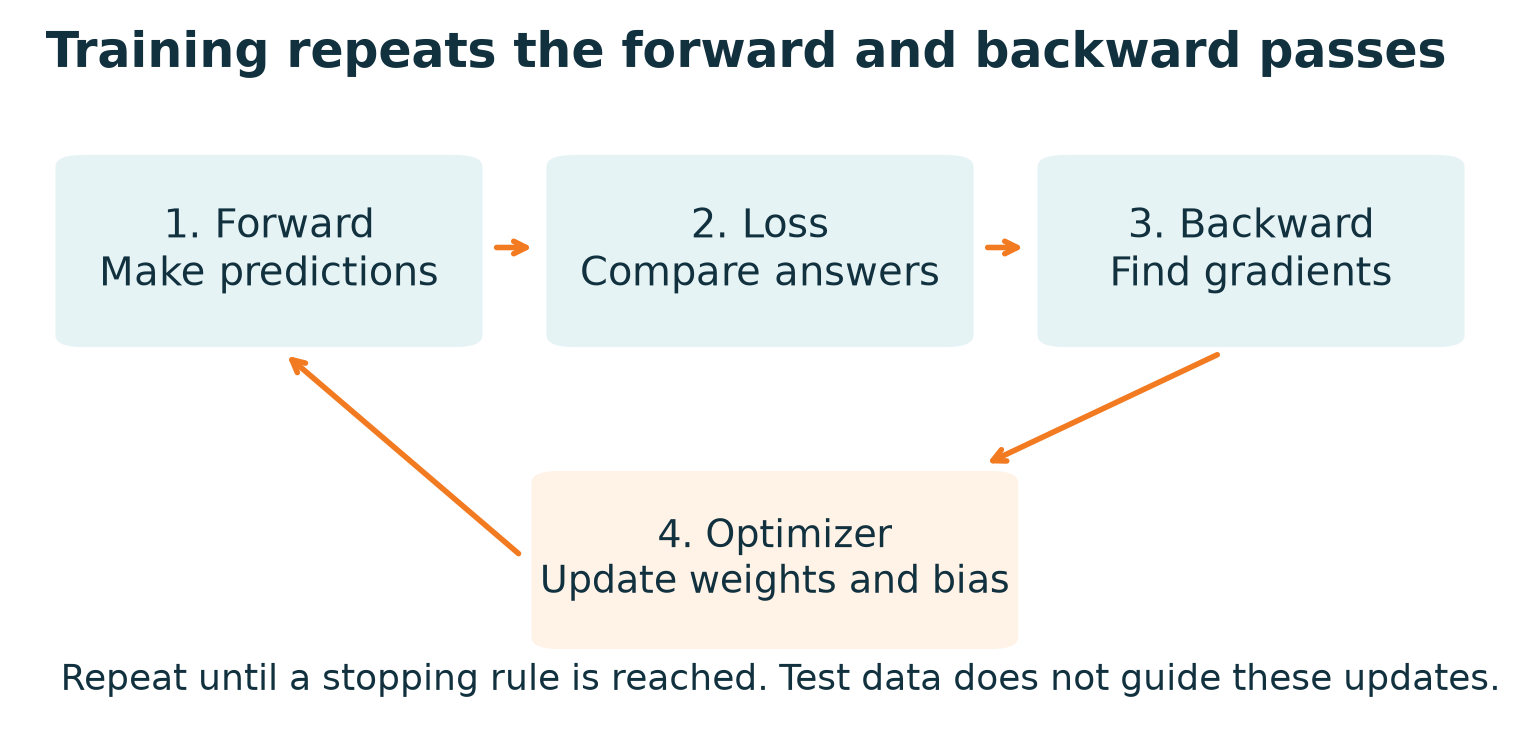

Forward propagation makes predictions. Loss compares them with targets. Backpropagation finds gradients. The optimizer changes parameters.

## 5. Load the built-in data

The dataset contains 569 records and 30 number features. Each record describes measurements from a cell sample. The target has two classes: **0 = malignant** and **1 = benign**. Malignant means cancerous; benign means non-cancerous. This is a coding example, not a tool for diagnosing a person.

We load the features directly. `head(3)` shows three rows so we can see what the table holds.

In [25]:
import pandas as pd  # Tables with named columns.

In [26]:
from sklearn.datasets import load_breast_cancer  # The dataset is bundled with scikit-learn.

In [27]:
data = load_breast_cancer()  # Load the same dataset used in the ANN resource.

In [28]:
X = pd.DataFrame(data.data, columns=data.feature_names)  # Give the 30 feature columns their names.

In [29]:
y = data.target  # Known class labels: 0 or 1.

In [30]:
X.head(3)  # A short preview; the notebook does not need a full EDA section.

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.8,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.8,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.0,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.5,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758


In [31]:
X.shape  # (569, 30): records first, features second.

(569, 30)

In [32]:
data.target_names  # The names follow label order: malignant, benign.

array(['malignant', 'benign'], dtype='<U9')

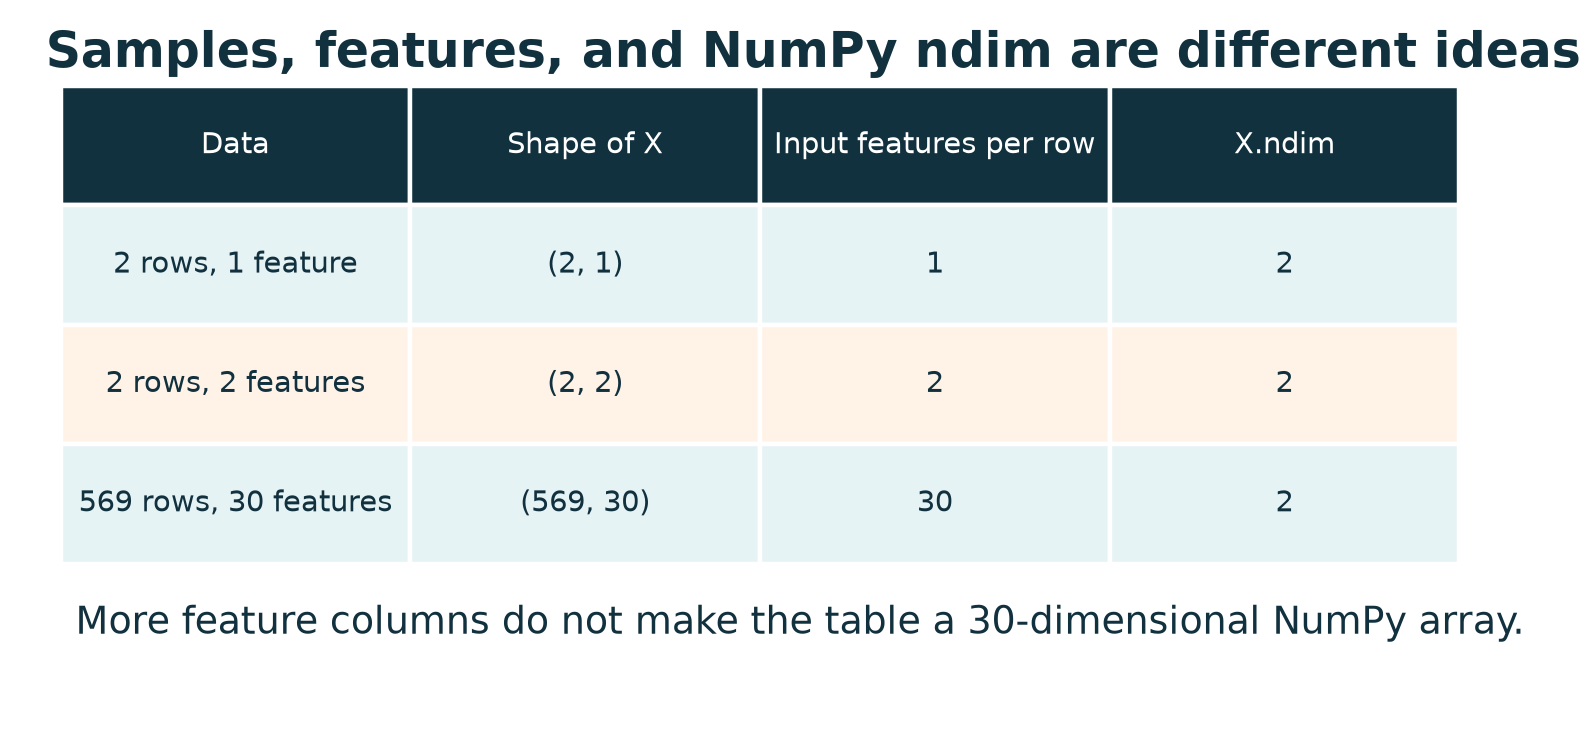

The breast cancer data has 30 features per record, but X is a two-dimensional table with rows and columns.

## 6. Split, then scale

A **test set** is a group of records kept out of training. `test_size=0.3` sets aside about 30% of the records. `random_state=10` fixes the shuffle so the example can be repeated. `stratify=y` keeps the class shares close to those in the full dataset.

**Scaling** puts features on comparable number scales. `fit_transform()` learns the training means and spreads, then changes the training values. `transform()` applies those same learned rules to test values. The test set must not choose its own scale.

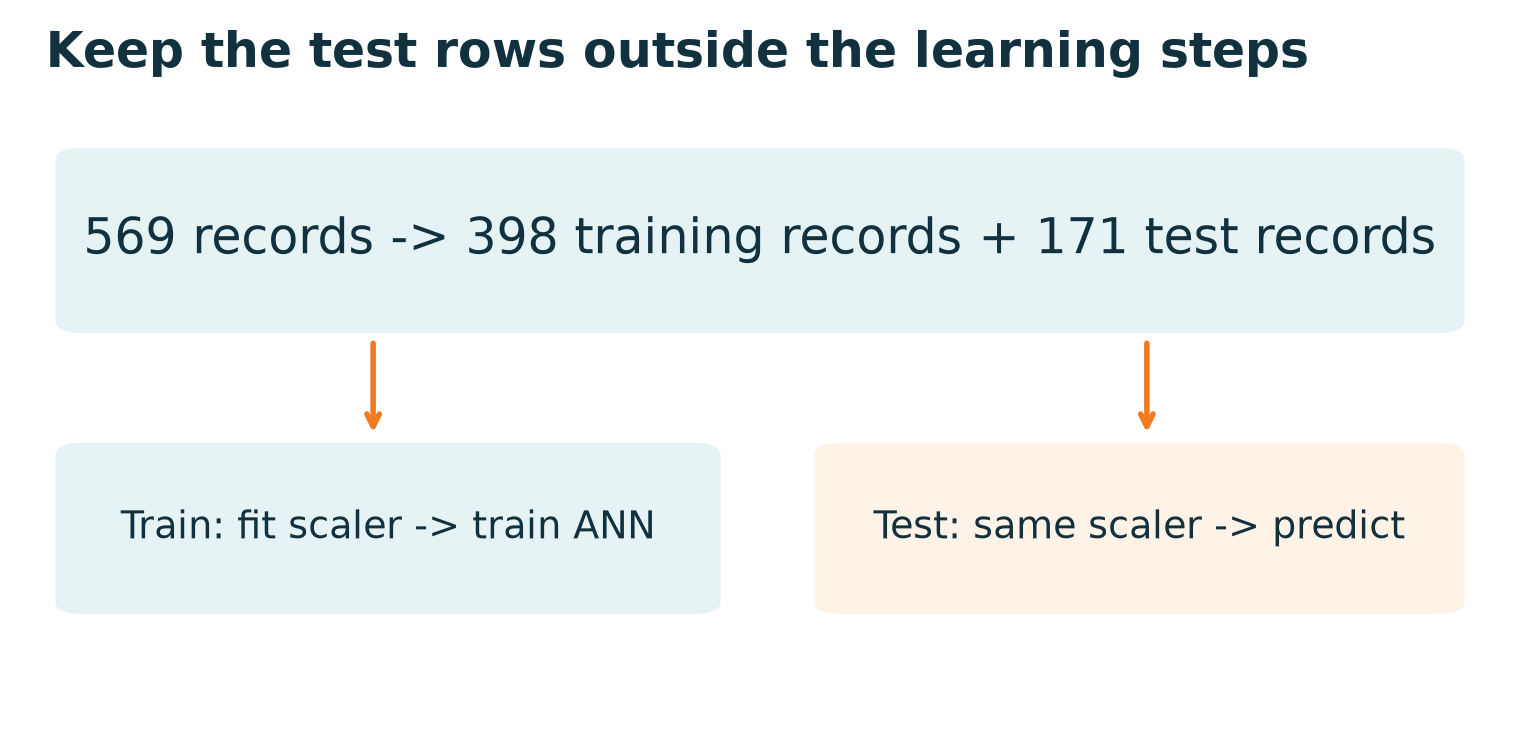

The scaler learns from training rows only. The same saved scaling is applied to test rows without learning from them.

In [33]:
from sklearn.model_selection import train_test_split  # Split records and their matching targets together.

In [34]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=10, stratify=y
)  # All four parts stay aligned: each target still belongs to its input row.

In [35]:
from sklearn.preprocessing import StandardScaler  # Subtract the training mean and divide by training spread.

In [36]:
scaler = StandardScaler()  # Create a scaler; it has not learned values yet.

In [37]:
X_train_scaled = scaler.fit_transform(X_train)  # Learn and apply the scale on training rows only.

In [38]:
X_test_scaled = scaler.transform(X_test)  # Reuse the scale. Do not call fit_transform() here.

## 7. Create the ANN

A **hyperparameter** is a setting chosen before training. A learned **parameter** is a weight or bias found during training.

- `hidden_layer_sizes=(10, 15, 10)` gives three hidden layers with 10, 15, and 10 neurons. It lists neither the input layer nor the output layer.
- `activation="relu"` uses ReLU in hidden neurons: negative scores become 0; positive scores stay as they are.
- `solver="adam"` chooses Adam, the optimizer that updates the weights and bias values.
- `learning_rate_init=0.05` sets the starting step size used in the resource. It is a chosen example value, not a value that is best for every dataset.
- `max_iter=500` allows up to 500 passes through the training set. Training can stop earlier when loss stops improving.
- `random_state=10` fixes the starting random choices so runs can be repeated.

`MLPClassifier` learns class probabilities using cross-entropy loss, also called log loss. It does not use the Mean Squared Error from our first number example.

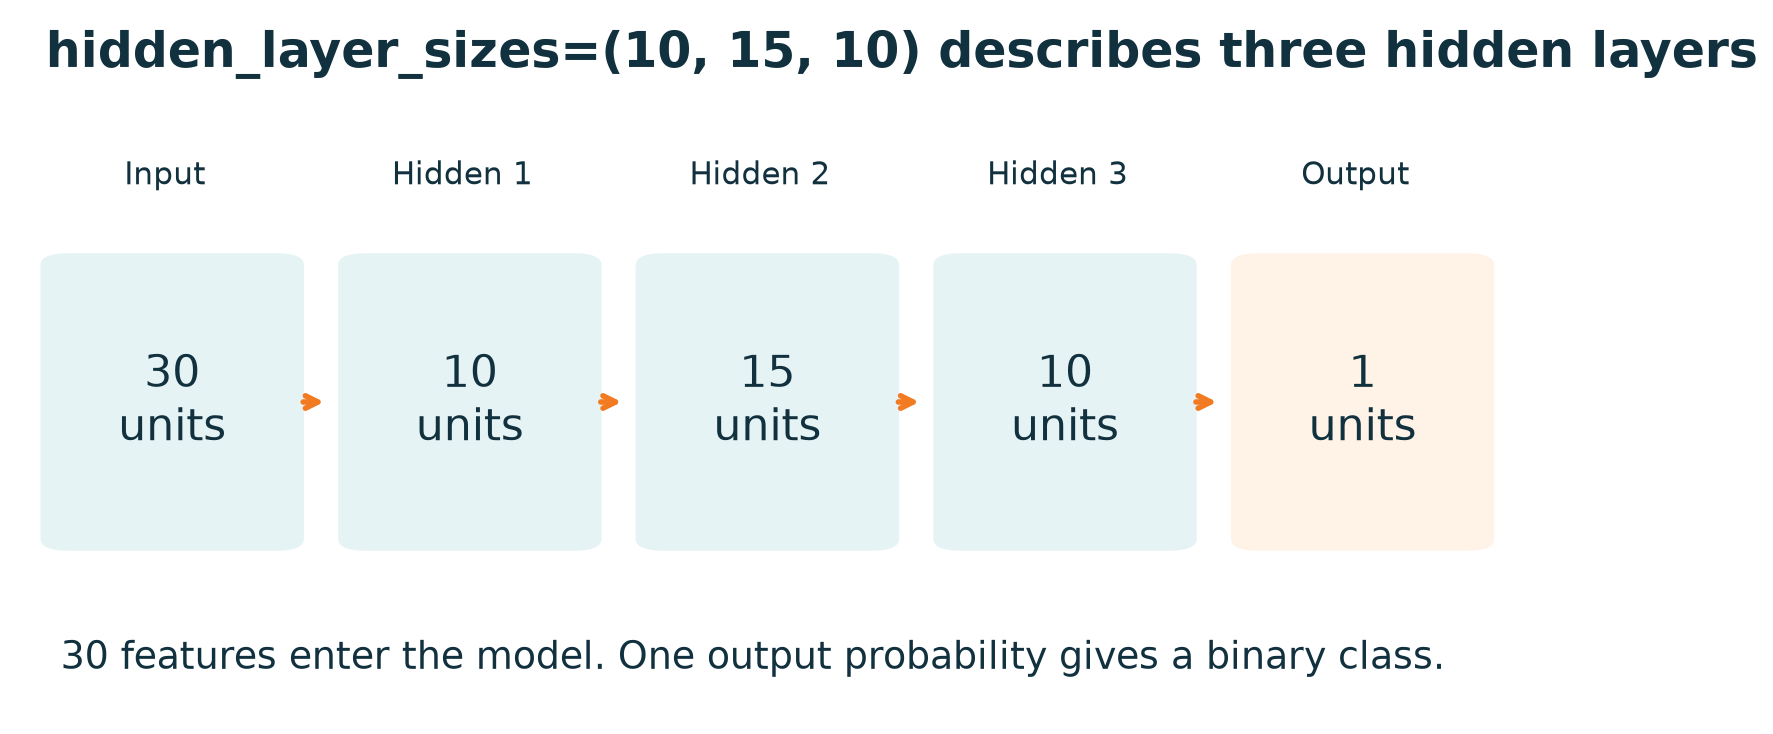

The tuple lists hidden layers only. Thirty inputs and the output unit are not included in (10, 15, 10).

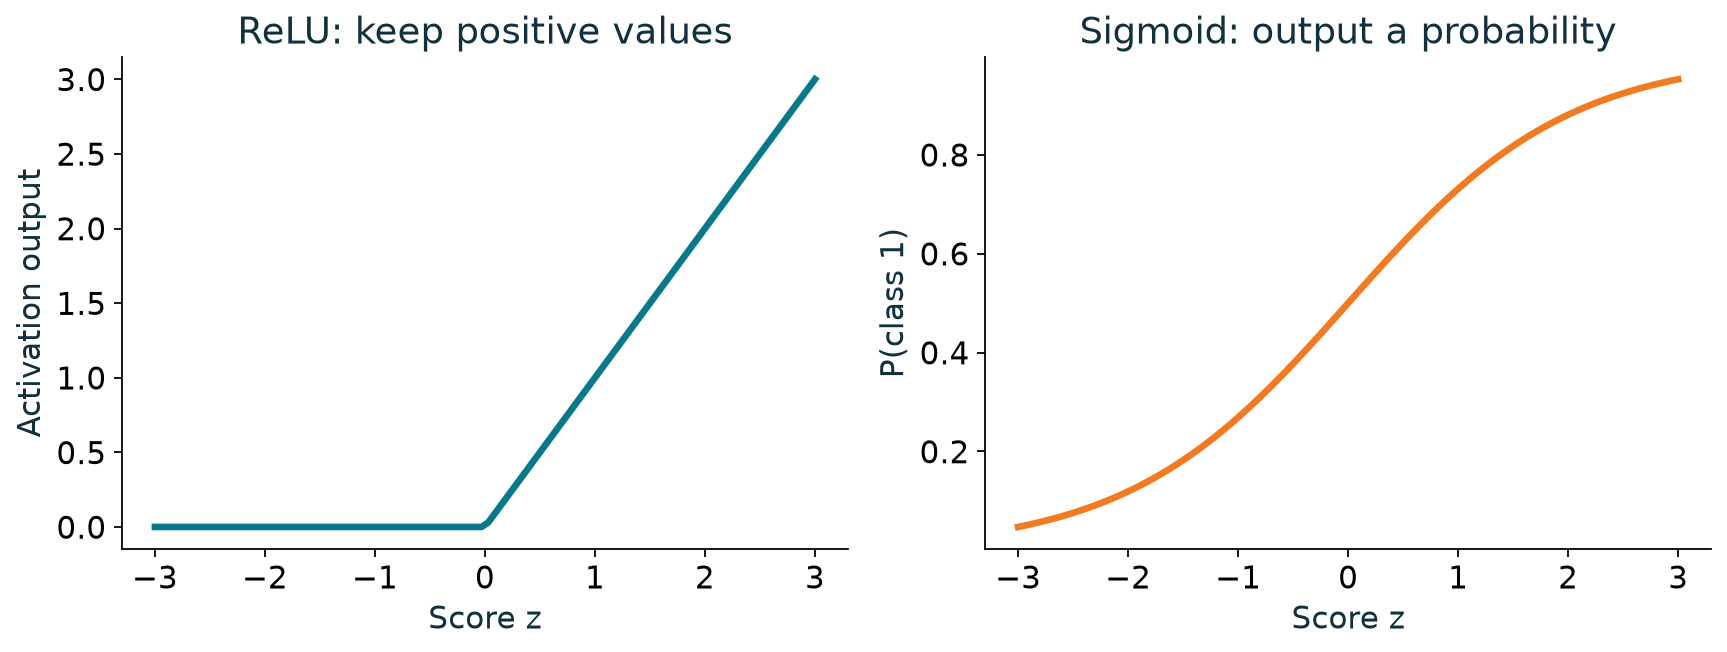

ReLU returns 0 for a negative score and keeps a positive score. Sigmoid maps a score to a probability between 0 and 1.

In [39]:
from sklearn.neural_network import MLPClassifier  # MLP means Multilayer Perceptron.

In [40]:
model = MLPClassifier(
    hidden_layer_sizes=(10, 15, 10),  # Three hidden layers from the resource.
    activation="relu",  # Hidden neurons use ReLU.
    solver="adam",  # Adam updates the weights and bias values.
    learning_rate_init=0.05,  # Starting step size from the resource example.
    max_iter=500,  # A limit, not a promise that all 500 passes are needed.
    random_state=10  # Repeat the same starting choices.
)

## 8. Fit and predict

`fit()` learns weights and biases using only training inputs and their known targets. `predict()` then uses the fitted model to choose a class for each test record. It receives no test targets.

In [41]:
model.fit(X_train_scaled, y_train)  # Training performs repeated forward and backward steps.

MLPClassifier(hidden_layer_sizes=(10, 15, 10), learning_rate_init=0.05,
              max_iter=500, random_state=10)

In [42]:
y_predict = model.predict(X_test_scaled)  # One class prediction for each test input.

In [43]:
y_predict[:10]  # Slicing shows only the first ten predictions.

array([1, 1, 1, 0, 0, 0, 1, 0, 1, 1])

## 9. Check the predictions

**Accuracy** is the share of correct class predictions. A **confusion matrix** also shows which types of mistake occurred. Rows below are actual labels; columns are predicted labels. Keep the label names visible: class 0 is malignant in this dataset.

In [44]:
from sklearn.metrics import accuracy_score  # Count correct predictions and divide by the test count.

In [45]:
accuracy_score(y_test, y_predict)  # Compare predictions with the held-out targets.

0.9766081871345029

In [46]:
actual = pd.Series(y_test, name="Actual class")  # Name the rows of the result table.

In [47]:
predicted = pd.Series(y_predict, name="Predicted class")  # Name its columns.

In [48]:
pd.crosstab(actual, predicted)  # Count each actual/predicted pair, as in the resource.

Predicted class,0,1
Actual class,,
0,61,3
1,1,106


## 10. See loss change during training

An **epoch** is one pass through the training records. `loss_curve_` stores the training loss after each pass. This loss includes the model's weight penalty as well as its classification loss. A weight penalty adds extra cost for large weights and can help reduce overfitting. A falling training loss is useful, but the held-out results are still needed.

In [49]:
import matplotlib.pyplot as plt  # Draw the saved training loss values.

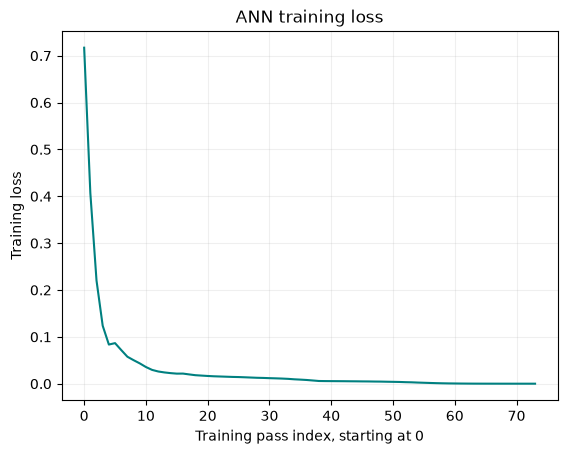

In [50]:
plt.plot(model.loss_curve_, color="teal")
plt.title("ANN training loss")
plt.xlabel("Training pass index, starting at 0")
plt.ylabel("Training loss")
plt.grid(alpha=0.2)
plt.show()  # A single chart cell keeps its plot commands together.